# Evaluating NBA Talent Production by College with SQL

## Project Description

In this data analysis project, I analyze the **NBA Draft Basketball Player Data (1989–2021)** Kaggle dataset to determine which college consistently produces the best NBA talent. Using SQL, I compare colleges across a variety of NBA performance metrics, including points per game (PPG), assists per game (APG), years active, box plus/minus (BPM), and win shares per 48 minutes (WS/48).

Rather than focusing solely on which schools produce the most NBA players, this project evaluates the quality, efficiency, and reliability of the players each college produces. For several metrics, I use SQL window functions to rank individual players within their college, showing exactly who is driving each school's average rather than relying on outside basketball knowledge to name notable alumni.

Since no single college leads in every metric, I also build a draft hit rate metric based on both career win shares and sustained per minute efficiency, since relying on career totals alone can unfairly penalize talented players with shorter or injury affected careers. Finally, I combine WS/48, BPM, and hit rate into one normalized value score to determine which college produces the most well rounded and consistent NBA talent overall, rather than just the highest scoring or most talked about players.


---------------------------------------------

## Data Cleaning

First, I will import and load the data, as well as clean the database in the next few cells.

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import plotly.graph_objects as go

nbadf = pd.read_csv("nbaplayersdraft.csv")
conn = sqlite3.connect("nbadf.db")
nbadf.to_sql("nbadf", conn, if_exists="replace", index=False)

1922

In [54]:
nbadf["college"] = nbadf["college"].replace("None", None)
nbadf["college"] = nbadf["college"].fillna("No College") 
nbadf["college"].isnull().sum()
nbadf.to_sql(
    "nbadf",
    conn,
    if_exists="replace",
    index=False
) 

career_cols = [
    "years_active",
    "games",
    "minutes_played",
    "points",
    "total_rebounds",
    "assists",
    "win_shares"
]

nbadf[career_cols] = nbadf[career_cols].fillna(0) 

nbadf[career_cols].isnull().sum() 

years_active      0
games             0
minutes_played    0
points            0
total_rebounds    0
assists           0
win_shares        0
dtype: int64

## Points Per Game (PPG)

Which colleges produce the highest-scoring NBA players? This query is limited to the top five highest-scoring players from each college, so the average PPG for each college is the average of those top five players. These five players are ranked from 1-5, with 1 having the highest PPG when organized by their college and 5 being the lowest. This query is also limited to round one, top ten picks with colleges having at least five drafted players that fall within that range. The difference from average column measures the difference between the player's PPG and the college's average PPG. In the next cell, this data will get graphed to make it easier to read.

In [38]:
window_ppg_query = """
WITH ranked AS (
    SELECT
        player,
        college,
        points_per_game AS ppg,
        AVG(points_per_game) OVER (PARTITION BY college) AS college_avg_ppg,
        points_per_game - AVG(points_per_game) OVER (PARTITION BY college) AS diff_from_avg,
        RANK() OVER (PARTITION BY college ORDER BY points_per_game DESC) AS rank_within_college
    FROM nbadf
    WHERE overall_pick <= 10
      AND college != 'No College'
      AND college IN (
          SELECT college FROM nbadf
          WHERE overall_pick <= 10
            AND college != 'No College'
          GROUP BY college
          HAVING COUNT(*) > 5
      )
),
top5 AS (
    SELECT *
    FROM ranked
    WHERE rank_within_college <= 5
),
top5_avg AS (
    SELECT college, AVG(ppg) AS top5_avg_ppg
    FROM top5
    GROUP BY college
)
SELECT t.*, a.top5_avg_ppg
FROM top5 t
JOIN top5_avg a ON t.college = a.college
ORDER BY a.top5_avg_ppg DESC, t.rank_within_college
"""
ranked_ppg = pd.read_sql(window_ppg_query, conn)
ranked_ppg

,player,college,ppg,college_avg_ppg,diff_from_avg,rank_within_college,top5_avg_ppg
0,Zion Williamson,Duke,25.7,13.113636,12.586364,1,21.14
1,Kyrie Irving,Duke,23.1,13.113636,9.986364,2,21.14
2,Jayson Tatum,Duke,20.9,13.113636,7.786364,3,21.14
3,Brandon Ingram,Duke,18.5,13.113636,5.386364,4,21.14
4,RJ Barrett,Duke,17.5,13.113636,4.386364,5,21.14
...,...,...,...,...,...,...,...
72,Steve Francis,Maryland,18.1,10.566667,7.533333,1,11.34
73,Walt Williams,Maryland,11.8,10.566667,1.233333,2,11.34
74,Joe Smith,Maryland,10.9,10.566667,0.333333,3,11.34
75,Chris Wilcox,Maryland,8.2,10.566667,-2.366667,4,11.34


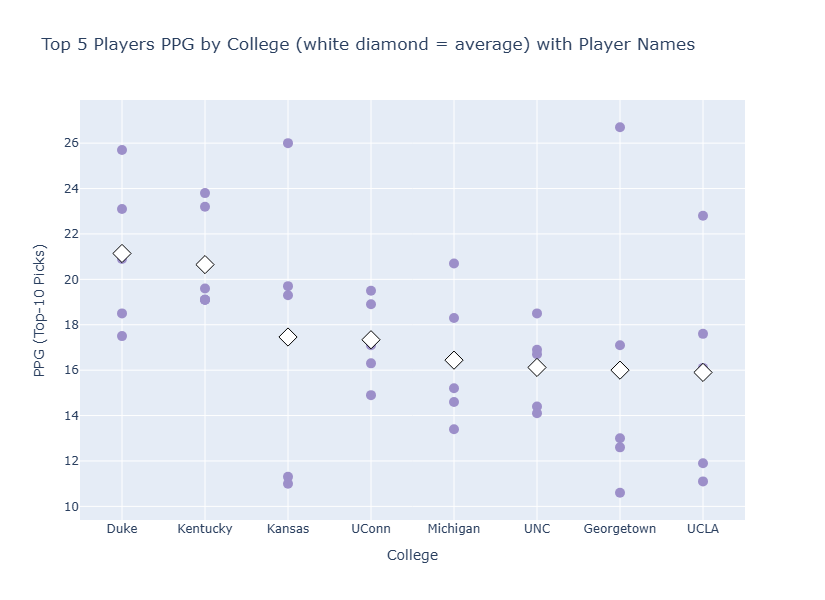

In [70]:
college_order = ranked_ppg.drop_duplicates("college").sort_values("top5_avg_ppg", ascending=False)["college"].tolist()
top_colleges = college_order[:8]
plot_df = ranked_ppg[ranked_ppg["college"].isin(top_colleges)]
fig = go.Figure()
for college in top_colleges:
    subset = plot_df[plot_df["college"] == college]
    fig.add_trace(go.Scatter(
        x=[college] * len(subset),
        y=subset["ppg"],
        mode="markers",
        marker=dict(color="#9C8FC9", size=10),
        text=subset["player"],
        hovertemplate="%{text}<br>PPG: %{y}<extra></extra>",
        showlegend=False
    ))
    avg = subset["top5_avg_ppg"].iloc[0]
    fig.add_trace(go.Scatter(
        x=[college],
        y=[avg],
        mode="markers",
        marker=dict(color="white", size=14, symbol="diamond", line=dict(color="black", width=1)),
        hovertemplate=f"{college} avg: {avg:.2f}<extra></extra>",
        showlegend=False
    ))
fig.update_layout(
    title="Top 5 Players PPG by College (white diamond = average) with Player Names",
    xaxis_title="College",
    yaxis_title="PPG (Top-10 Picks)",
    height=600
)
fig.show()

After analyzing the graph, Duke ranks first in average PPG among top-10 picks, with its top five players averaging 21.14 PPG. Zion Williamson leads Duke with the highest average PPG across his career at 25.7 PPG, which is 4.56 points higher than Duke's average. However, Zion has missed significant playing time in the past few seasons due to injuries, and PPG does not necessarily take that into account, as it only reflects performance in games actually played, and it doesn't capture availability. 

Other colleges also produce high-scoring outliers. Joel Embiid (Kansas, 26 PPG), Allen Iverson (Georgetown, 26.7 PPG), and Russell Westbrook (UCLA, 22.8 PPG) each have similarly large diff_from_avg values (+8.54, +10.7, and +6.9 respectively), showing that a single elite scorer can meaningfully lift a college's top-five average even when the rest of that college's cohort is more modest.

However, it is important to note that this ranking reflects each college's top five scorers specifically, not the full average across all drafted players. A college with more total draft picks may have a lower all-player average even if its best players outscore Duke's, since weaker picks dilute the full-roster average. If averaging all players PPG that were round one, top-10 picks, Kentucky would have been at the top.

Lastly, it is important to understand that raw PPG does not necessarily mean a player is great. While PPG is an important and telling metric, as it shows how consistent a player's point averages were across their entire career through various seasons, there are other metrics that help tell a bigger story. Win Share per 48 minutes - which estimates the number of wins a player contributes to their team in 48 minutes (a whole game) and is later referenced in this project - is another key detail to providing insight onto a player's impact on the court and their team. Duke additionally tops the list with the highest win share per 48 mins metric, and Zion Williamson's WS/48 of 0.189 is well above Duke's average of 0.156, which indicates his strong per-minute impact, though this still only reflects the seasons/games he's actually played, not his availability.

## Longevity

Which colleges produce NBA players with the highest longevity or stay in the league the most amount of years?

In [40]:
longquery = """
SELECT
    college,
    COUNT(*) AS drafted_players,
    AVG(years_active) AS longevity
FROM nbadf
WHERE overall_pick <= 10
GROUP BY college
HAVING COUNT(*) > 5
ORDER BY longevity DESC
"""

longevity = pd.read_sql(longquery, conn)
longevity


,college,drafted_players,longevity
0,Florida,6,13.333333
1,UNC,11,13.000000
2,Georgia Tech,6,12.333333
3,UConn,11,12.272727
4,Georgetown,7,12.000000
5,Michigan,9,10.888889
6,Syracuse,6,10.666667
7,Arizona,13,10.461538
8,Kansas,9,9.888889
9,Texas,8,9.750000


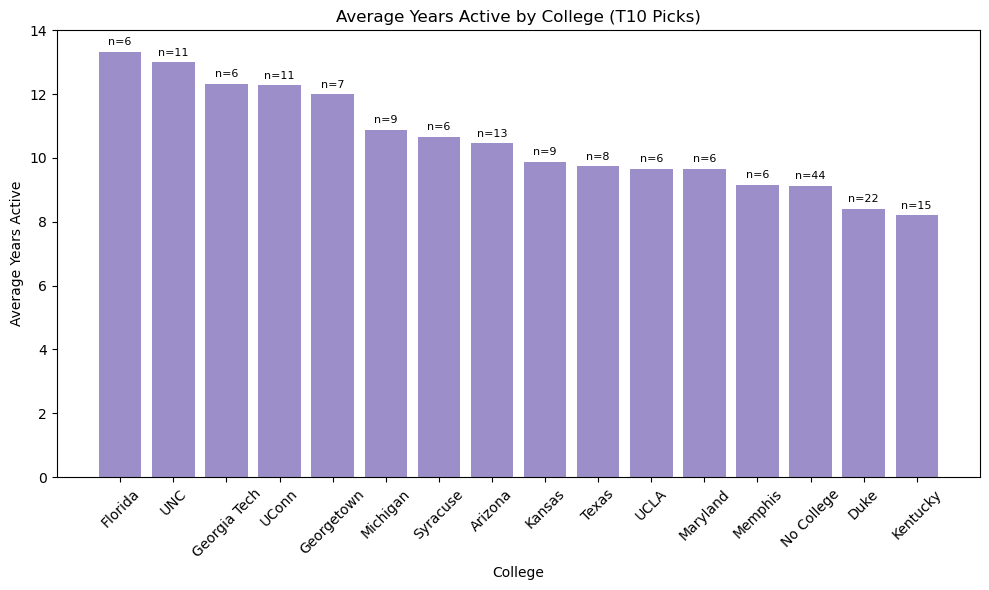

In [58]:
fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.bar(longevity["college"], longevity["longevity"], color="#9C8FC9")

ax.set_title("Average Years Active by College (T10 Picks)", color="black")
ax.set_xlabel("College", color="black")
ax.set_ylabel("Average Years Active", color="black")
ax.tick_params(axis="x", colors="black", labelrotation=45)
ax.tick_params(axis="y", colors="black")

for spine in ax.spines.values():
    spine.set_color("black")

for bar, n in zip(bars, longevity["drafted_players"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"n={n}",
        ha="center",
        fontsize=8,
        color="black"
    )

plt.tight_layout()
plt.show()

After analyzing the graph, Florida ranks the highest among colleges with their 6 round one top-10 drafted players averaged 13.33 years in the NBA. A notable alumni from Florida who is driving this high average is Al Horford, who was drafted 3rd overall and was a key veteran piece to the Celtics championship in 2024, ultimately playing 19 seasons so far. UNC is followed closely behind with an average of 13.0 years, however it is important to note that they produced 11 round one top-10 drafted players, which may have contributed to a dip in the average due to the variance between 11 players vs 6 from Florida. 

It may be surprising to see Duke and Kentucky near the bottom despite producing high-scoring players in the NBA from the previous PPG analysis. However, both Duke and Kentucky produced many NBA players, with Duke producing 22 drafted players and Kentucky producing 15. Due to these high numbers, some players turn out to be busts, or end up being in and out of the league or not playing up to their expected potential, which can bring down the college's average in longevity despite producing strong, household name players.

Lastly, it is important to note longevity does not distinguish between a starter and a bench player. A bench player who barely gets minutes but still has a contract could technically last longer than players who may be peak stars but then face a career-ending injury. As a result, this metric does penalize explosive players that WS/48 actually embraces if these players face injuries or other complications that can pause or end their career. Basically, longevity only captures years in the league, not years as a productive starter.

## Assists Per Game (APG)

Which colleges produce NBA players with the highest career average assists per game?

In [42]:
astquery = """
SELECT
    college,
    COUNT(*) AS drafted_players,
    AVG(average_assists) AS avg_ast
FROM nbadf
WHERE overall_pick <= 10
GROUP BY college
HAVING COUNT(*) > 5
ORDER BY avg_ast DESC
"""

assists = pd.read_sql(astquery, conn)
assists

,college,drafted_players,avg_ast
0,UCLA,6,5.250000
1,Florida,6,3.383333
2,Kentucky,15,3.273333
3,Georgia Tech,6,3.250000
4,Memphis,6,3.100000
5,Syracuse,6,2.633333
6,Michigan,9,2.622222
7,Arizona,13,2.515385
8,Duke,22,2.513636
9,Texas,8,2.375000


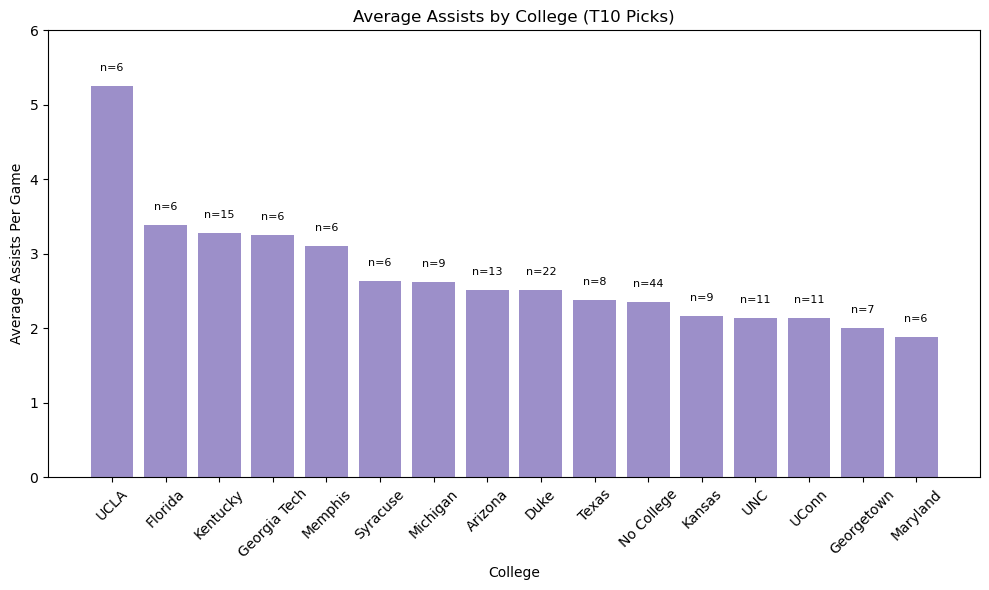

In [59]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

bars = ax.bar(assists["college"], assists["avg_ast"], color="#9C8FC9")

ax.set_title("Average Assists by College (T10 Picks)", color="black")
ax.set_xlabel("College", color="black")
ax.set_ylabel("Average Assists Per Game", color="black")
ax.tick_params(axis="x", colors="black", labelrotation=45)
ax.tick_params(axis="y", colors="black")

ax.set_ylim(0, 6)

for spine in ax.spines.values():
    spine.set_color("black")

for bar, n in zip(bars, assists["drafted_players"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"n={n}",
        ha="center",
        fontsize=8,
        color="black"
    )

plt.tight_layout()
plt.show()

After analyzing this graph, UCLA tops the list with the average assists per game across their top-10 picks being 5.25, which in comparison with Florida's 3.38 in second place, being way higher. A notable alumni from UCLA who drove this high APG average is none other than Russell Westbrook. Russell Westbrook is regarded as one of the best point guards in NBA history, known as "Mr. Triple Double" due to his consistent triple-double performances, being the only player in NBA history to average a triple-double for an entire season multiple times. This statistic is a big driving factor for why the difference between Florida and UCLA is massive, as Westbrook has averaged 8.0 APG across his 17+ year career compared to only around 3.2 APG from Florida's leading APG player, Al Horford. 

It is common for assists to be structurally tied to point guards. An elite point guard will almost always average more assists than a center or forward, because statistically these positions generally cannot rack up assists in the same way guards can. 

Although Westbrook's averages are the reason for UCLA's domination in this chart, it is also important to note that UCLA has only produced six top-10 drafts, compared to some other colleges who have produced ten or twenty plus. Florida also produced six top-10 picks, yet their APG average is far lower, which is consistent with the fact that Florida's leading contributor, Al Horford, is a forward/center, not a guard. This contrast suggests UCLA's high ranking isn't necessarily about developing better distributors overall, but about having drafted one generational point guard. Westbrook is a breakout example of a successful, high-caliber playmaking guard, which skyrocketed UCLA's APG average, but is not telling of UCLA as a whole.

Due to this important distinction, APG is **not** utilized in my final analysis of value because APG from a college does not necessarily capture the different positions of players that come out of these schools. This ranking is mostly driven by position mix rather than program strength, so it is not accurate to use APG alone to judge a school's ability to produce great talent.

## Win Shares per 48 Minutes

Which college produces NBA players with the highest win shares per 48 minutes (WS/48)? WS/48 estimates how many wins a player contributes per 48 minutes played. Higher values indicate a greater impact on winning. 

In [44]:
window_ws48_query = """
WITH ranked AS (
    SELECT
        player,
        college,
        win_shares_per_48_minutes AS ws48,
        AVG(win_shares_per_48_minutes) OVER (PARTITION BY college) AS college_avg_ws48,
        win_shares_per_48_minutes - AVG(win_shares_per_48_minutes) OVER (PARTITION BY college) AS diff_from_avg,
        RANK() OVER (PARTITION BY college ORDER BY win_shares_per_48_minutes DESC) AS rank_within_college
    FROM nbadf
    WHERE overall_pick <= 10
      AND college != 'No College'
      AND college IN (
          SELECT college FROM nbadf
          WHERE overall_pick <= 10
            AND college != 'No College'
          GROUP BY college
          HAVING COUNT(*) > 5
      )
),
top5 AS (
    SELECT *
    FROM ranked
    WHERE rank_within_college <= 5
),
top5_avg AS (
    SELECT college, AVG(ws48) AS top5_avg_ws48
    FROM top5
    GROUP BY college
)
SELECT t.*, a.top5_avg_ws48
FROM top5 t
JOIN top5_avg a ON t.college = a.college
ORDER BY a.top5_avg_ws48 DESC, t.rank_within_college
"""
ranked_ws48 = pd.read_sql(window_ws48_query, conn)
ranked_ws48

,player,college,ws48,college_avg_ws48,diff_from_avg,rank_within_college,top5_avg_ws48
0,Zion Williamson,Duke,0.189,0.090636,0.098364,1,0.1564
1,Kyrie Irving,Duke,0.166,0.090636,0.075364,2,0.1564
2,Elton Brand,Duke,0.151,0.090636,0.060364,3,0.1564
3,Grant Hill,Duke,0.138,0.090636,0.047364,4,0.1564
4,Jayson Tatum,Duke,0.138,0.090636,0.047364,4,0.1564
...,...,...,...,...,...,...,...
70,Carmelo Anthony,Syracuse,0.120,0.062667,0.057333,1,0.0782
71,Derrick Coleman,Syracuse,0.119,0.062667,0.056333,2,0.0782
72,Billy Owens,Syracuse,0.078,0.062667,0.015333,3,0.0782
73,Wesley Johnson,Syracuse,0.038,0.062667,-0.024667,4,0.0782


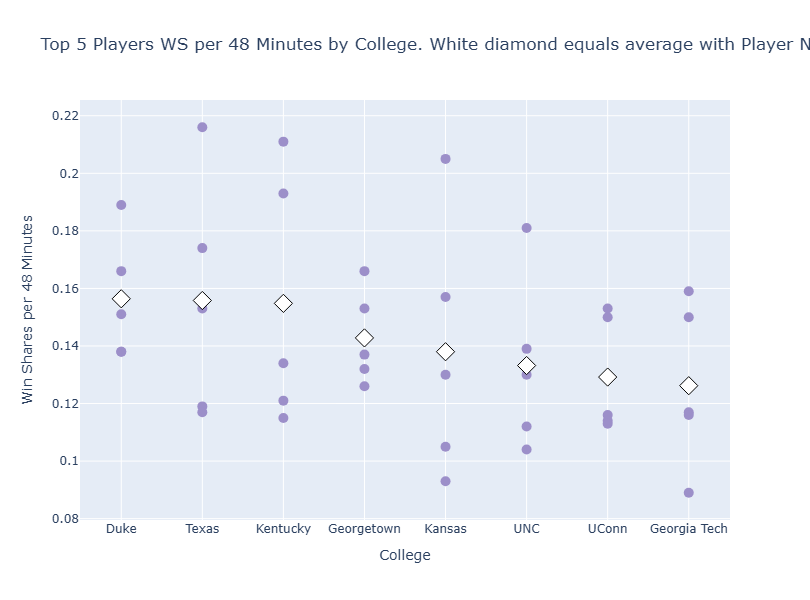

In [69]:
college_order_ws48 = ranked_ws48.drop_duplicates("college").sort_values("top5_avg_ws48", ascending=False)["college"].tolist()
top_colleges_ws48 = college_order_ws48[:8]
plot_df_ws48 = ranked_ws48[ranked_ws48["college"].isin(top_colleges_ws48)]

fig = go.Figure()

for college in top_colleges_ws48:
    subset = plot_df_ws48[plot_df_ws48["college"] == college]
    fig.add_trace(go.Scatter(
        x=[college] * len(subset),
        y=subset["ws48"],
        mode="markers",
        marker=dict(color="#9C8FC9", size=10),
        text=subset["player"],
        hovertemplate="%{text}<br>WS/48: %{y}<extra></extra>",
        showlegend=False
    ))
    avg = subset["top5_avg_ws48"].iloc[0]
    fig.add_trace(go.Scatter(
        x=[college],
        y=[avg],
        mode="markers",
        marker=dict(color="white", size=14, symbol="diamond", line=dict(color="black", width=1)),
        hovertemplate=f"{college} avg: {avg:.3f}<extra></extra>",
        showlegend=False
    ))

fig.update_layout(
    title="Top 5 Players WS per 48 Minutes by College. White diamond equals average with Player Names",
    xaxis_title="College",
    yaxis_title="Win Shares per 48 Minutes",
    height=600
)
fig.show()

In this graph, Duke has the highest average WS/48 among its top-five players that were top-10 picks in the draft. This finding was mentioned earlier in this project, as, in combination with PPG, Duke is constantly producing talent that has both high averages in PPG and WS/48. WS/48 is a metric that measures how much a player contributes per 48 minutes, or a whole game. This metric captures per-minute impact regardless of shots taken or how many minutes a player gets. Unlike PPG, WS/48 is a more accurate metric that provides insight into the impact a player brings to a team. 

Zion Williamson, who averaged the highest PPG for Duke, also has the highest WS/48 at 0.189. It is important to contextualize this number. In the NBA, a 0.100 WS/48 represents the league average, or a replacement-level player. A 0.200 is an indicator of an elite level of play, or a player who performs significantly above average. A 0.300+ WS/48 is an indicator of an all-time great player. However, a 0.300+ WS/48 is normally associated with a season, not a whole career. It is near impossible for a player to have a 0.300+ WS/48 average over their whole career, because this win share average is normally associated with an MVP performance or a player's peak, which is one part of their career, not their entire career. A 0.189 average over a career is nearly double the average, and a sign of a high-end starter or a player at the threshold of an All-Star. However, it is important to note that Zion Williamson is a relatively new player in the NBA (2019), so his career has been short compared to others. He had a breakout rookie season and has only played a few seasons since, with others cut short due to injury, which could lead to an inflated WS/48. 

In this chart, some other notable players with a high WS/48 are Kevin Durant (0.216, Texas), Anthony Davis (0.211, Kentucky), and Joel Embiid (0.205, Kansas). These win shares of 0.200+ indicate an All-Star-caliber, consistent, high-scoring, and impactful player, which makes sense, as Kevin Durant, Anthony Davis, and Joel Embiid are all franchise pieces who have led teams successfully.

It is interesting that despite Georgetown being near the lower end of PPG averages among drafted players, it sits toward the middle in WS/48 averages, with the school averaging a WS/48 of 0.143. Alonzo Mourning tops the list of Georgetown's players with the highest WS/48 at 0.166, proving that he was a productive and elite player. However, it is crucial to highlight that this high career WS/48 is due to his defensive ability rather than his offensive ability. Zion Williamson's WS/48, in contrast, is driven almost entirely by his offensive efficiency and finishing ability near the basket, rather than defense-driven value like Mourning's.
Because WS/48 captures both offensive and defensive contributions in a single per-minute rate, it will be included in the final value analysis, since it helps distinguish good players from truly great ones — something PPG alone cannot do.



## Box Plus/Minus

Which college produces NBA players with the highest Box Plus-Minus (BPM)? BPM estimates a player's overall on-court impact relative to a league-average player per 100 possessions. Higher values indicate a greater net contribution to team performance on both ends of the floor.

In [46]:
boxpm = """
SELECT
    college,
    COUNT(*) AS drafted_players,
    AVG(box_plus_minus) AS avg_boxpm
FROM nbadf
WHERE overall_pick <= 10
    AND college != 'No College'
GROUP BY college
HAVING COUNT(*) > 5
ORDER BY avg_boxpm DESC
"""

average_boxpm = pd.read_sql(boxpm, conn)
average_boxpm

,college,drafted_players,avg_boxpm
0,UCLA,6,1.333333
1,Florida,6,1.083333
2,Georgetown,7,0.885714
3,Kentucky,15,0.466667
4,Georgia Tech,6,0.400000
5,UConn,11,0.381818
6,Texas,8,0.275000
7,Arizona,13,-0.115385
8,UNC,11,-0.290909
9,Duke,22,-0.290909


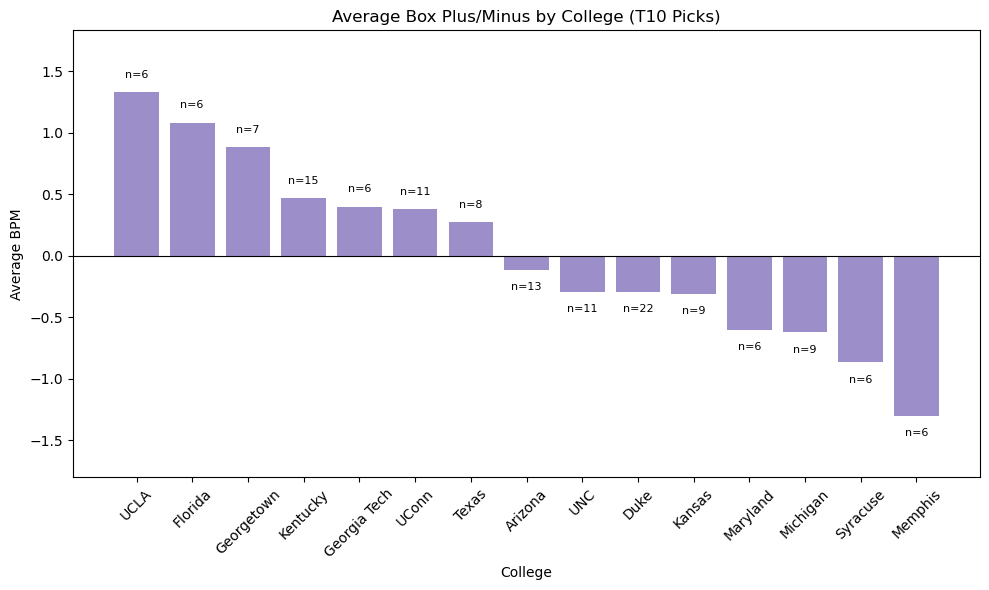

In [71]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

buffer = 0.5
ax.set_ylim(
    min(average_boxpm["avg_boxpm"]) - buffer,
    max(average_boxpm["avg_boxpm"]) + buffer,
)

bars = ax.bar(average_boxpm["college"], average_boxpm["avg_boxpm"], color="#9C8FC9")

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Average Box Plus/Minus by College (T10 Picks)", color="black")
ax.set_xlabel("College", color="black")
ax.set_ylabel("Average BPM", color="black")
ax.tick_params(axis="x", colors="black", labelrotation=45)
ax.tick_params(axis="y", colors="black")

for spine in ax.spines.values():
    spine.set_color("black")

for bar, n in zip(bars, average_boxpm["drafted_players"]):
    height = bar.get_height()
    offset = 0.1 if height >= 0 else -0.1
    va = "bottom" if height >= 0 else "top"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + offset,
        f"n={n}",
        ha="center",
        va=va,
        fontsize=8,
        color="black",
    )

plt.tight_layout()
plt.show()

Unlike the previous two sections, this BPM analysis reflects the average across all drafted top-10 picks per college, rather than just each college's top five. I made this choice deliberately, as PPG and WS/48 were used to identify each school's ceiling talent, while BPM is used to test whether a college's overall draft class holds up once its weaker picks are included, not just its stars.

Under this lens, the results shift dramatically. UCLA leads with an average BPM of 1.33, followed by Florida (1.08) and Georgetown (0.89), all schools that have produced a relatively small number of top-10 picks (6, 6, and 7, respectively). Duke, which dominated both the PPG and WS/48 sections, actually ranks 9th here with a negative average BPM of -0.29, tied with UNC. This finding is consistent with the same volume-versus-rate tension raised in the Longevity and APG sections, now showing up in a third metric. Duke has produced 22 top-10 picks, the most of any school in this dataset. While a handful of those picks, like Zion Williamson, are genuinely elite, a much larger group of average-to-below-average picks pulls Duke's overall average into negative territory. UCLA, by contrast, has only 6 top-10 picks, so one standout talent like Russell Westbrook can lift the college's average without being diluted by a large pool of weaker selections.

This distinction matters for how "program value" should actually be interpreted. A team drafting based on ceiling talent alone might reasonably prioritize Duke, since it has repeatedly produced elite, high-impact players. But a team concerned with hit rate and draft-pick reliability would see Duke's overall average as a warning sign, as a large draft class doesn't guarantee consistent quality, and a college with fewer picks but a higher hit rate, like UCLA or Florida, may represent a safer investment on average, even if its raw pool of NBA talent is smaller.

Because BPM captures overall two-way value and, in this format, reflects program-wide consistency rather than just peak talent, it will be included in the final value analysis alongside WS/48 and draft hit rate.

## Hit Rate

Which college has the highest hit rate, or produces the highest percentage of alumni who go on to have successful NBA careers?

In [48]:
query3 = """
SELECT
    college,
    COUNT(*) AS drafted_players,
    SUM(CASE 
        WHEN win_shares >= 25 
             OR (win_shares_per_48_minutes >= 0.150 AND games >= 150) 
        THEN 1 ELSE 0 END) AS successful_players
FROM nbadf
WHERE overall_pick <= 10
  AND college != 'No College'
GROUP BY college
HAVING COUNT(*) > 5
"""
results = pd.read_sql(query3, conn)
results["hit_rate"] = results["successful_players"] / results["drafted_players"]
results.sort_values("hit_rate", ascending=False)

,college,drafted_players,successful_players,hit_rate
3,Georgetown,7,6,0.857143
4,Georgia Tech,6,5,0.833333
2,Florida,6,5,0.833333
13,UConn,11,9,0.818182
14,UNC,11,8,0.727273
8,Memphis,6,4,0.666667
7,Maryland,6,4,0.666667
12,UCLA,6,4,0.666667
11,Texas,8,5,0.625000
0,Arizona,13,8,0.615385


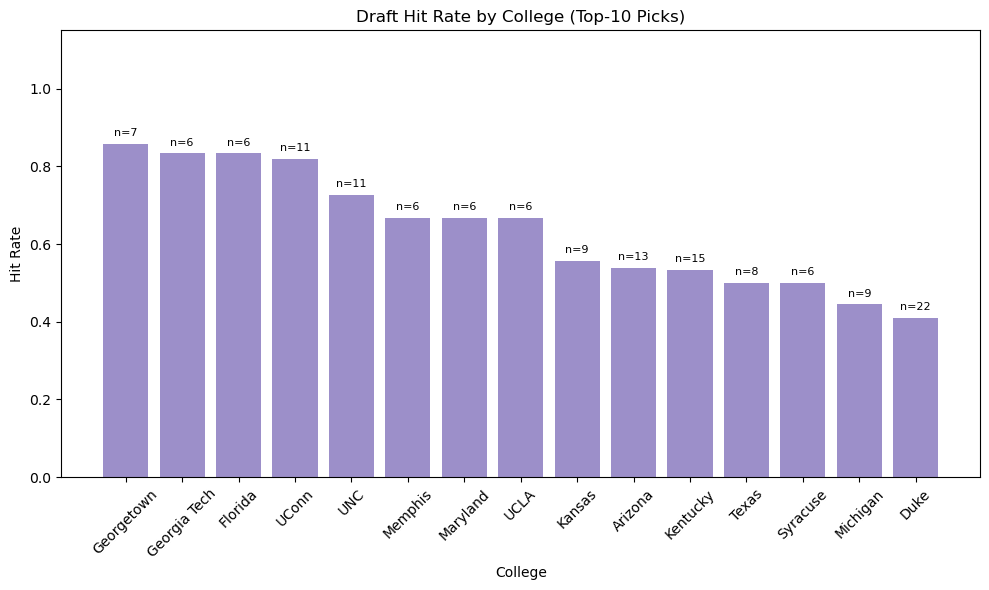

In [72]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

hit_rate_sorted = results.sort_values("hit_rate", ascending=False)

bars = ax.bar(hit_rate_sorted["college"], hit_rate_sorted["hit_rate"], color="#9C8FC9")

ax.set_title("Draft Hit Rate by College (Top-10 Picks)", color="black")
ax.set_xlabel("College", color="black")
ax.set_ylabel("Hit Rate", color="black")
ax.set_ylim(0, 1.15)
ax.tick_params(axis="x", colors="black", labelrotation=45)
ax.tick_params(axis="y", colors="black")

for spine in ax.spines.values():
    spine.set_color("black")

for bar, n in zip(bars, hit_rate_sorted["drafted_players"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"n={n}",
        ha="center",
        fontsize=8,
        color="black"
    )

plt.tight_layout()
plt.show()

This is the final analysis regarding which team has the best hit rate, or is the most successful is producing successful players in the NBA. Georgetown leads all colleges with the highest hit rate of 85.7%, with 6 of its 7 players that were drafted within the top 10 to go and have a successful NBA career. Following closely behind is Georgia Tech, with a hit rate of 83.3%, with 5 of its 6 players having a successful NBA career. But what is a "successful career"?

It is important to understand what constitutes this so-called "hit rate". This hit rate is defined by three things: win shares, win shares per 48 minutes, and games played spanning their entire career. If the win share is above 25 or has a WS/48 greater than 0.150, and has a minimum of 150 games played their entire career, then the player's career is deemed successful. A WS of 25 or above indicates that a player was a consistent starter or a high-impact sixth man for many years. By having a WS requirement of 25 or higher, it filters out mere role players or solid players that were second options but still had long careers, since WS is increased by time spent in the league. Historically, only about 40–50% of first-round picks reach the 25 Win Share mark. Achieving this total means a player didn't just stick in the league. Rather, they provided significant surplus value over a replacement-level player for a substantial portion of their career. Basically, WS distinguishes between players who played and players who **mattered**.

Additionally, a career WS/48 of 0.150 represents a few things. Firstly, as previously mentioned, the league average WS/48 is 0.100. A WS/48 of 0.150 represents a player who contributes 50% more winning value per minute than an average player, which separates between "role players" and "good starters".

A career rate of 0.150 typically places a player in the All-Star or near All-Star category. For context, legends like Stephen Curry (0.201), Tim Duncan (0.209), and Kevin Durant (0.214) are well above this, but many respected Hall of Famers and perennial All-Stars hover right around or just above 0.150. Unlike total Win Shares (where 25 can include players with long careers but modest impact), WS/48 measures efficiency. Some players that are considered exceptional stars sometimes fall below the 0.150 WS/48 mark, which is why the hit rate is an OR statement rather than an AND statement. For example, Russell Westbrook's WS/48 is 0.144, but as previously mentioned, he is an elite point guard, regarded as one of the best to ever play the position.

The 150 games requirement actually excludes some previously mentioned players like Zion Williamson. From my perspective, a player should at least play 150 games before they can be brought into the conversation of "successful". Zion Williamson's career has been interrupted by injuries, and therefore it is not conclusive to say yet whether or not he is a successful player. The 150 games minimum represents about 1.83 standard regular seasons, as 1 season is 82 games per team. However, including a postseason, a team that goes as far as winning the NBA Championship will play a minimum of 98 games. Therefore, 150 games could consist of 1.83 regular seasons or a deep playoff run and a little bit of another season.

## Overall Value Score

Which college produces the most well-rounded and consistent NBA talent overall? This composite score combines three normalized metrics, win shares per 48 minutes, box plus-minus, and hit rate, into a single rating. Higher values reflect a stronger overall track record across production, efficiency, and long-term success, rather than dominance in any one category alone.

In [73]:
final_value = """
SELECT
    college,
    COUNT(*) AS drafted_players,
    SUM(CASE WHEN win_shares > 25 THEN 1 ELSE 0 END) AS successful_players
FROM nbadf
WHERE overall_pick <= 10
  AND college != 'No College'
GROUP BY college
HAVING COUNT(*) > 5
"""
results = pd.read_sql(query10, conn)
results["hit_rate"] = results["successful_players"] / results["drafted_players"]

ws48_college = ranked_ws48.drop_duplicates("college")[["college", "top5_avg_ws48"]].rename(
    columns={"top5_avg_ws48": "avg_ws48"}
)

final = ws48_college.merge(average_boxpm[["college", "avg_boxpm"]], on="college")
final = final.merge(results[["college", "hit_rate"]], on="college")

for col in ["avg_ws48", "avg_boxpm", "hit_rate"]:
    final[col + "_norm"] = (final[col] - final[col].min()) / (final[col].max() - final[col].min())

final["value_score"] = final[["avg_ws48_norm", "avg_boxpm_norm", "hit_rate_norm"]].mean(axis=1)

final = final.sort_values("value_score", ascending=False)
final

,college,avg_ws48,avg_boxpm,hit_rate,avg_ws48_norm,avg_boxpm_norm,hit_rate_norm,value_score
3,Georgetown,0.1428,0.885714,0.857143,0.826087,0.830018,1.000000,0.885368
9,Florida,0.1210,1.083333,0.833333,0.547315,0.905063,0.946860,0.799746
7,Georgia Tech,0.1262,0.400000,0.833333,0.613811,0.645570,0.946860,0.735413
6,UConn,0.1292,0.381818,0.818182,0.652174,0.638665,0.913043,0.734628
10,UCLA,0.1106,1.333333,0.666667,0.414322,1.000000,0.574879,0.663067
2,Kentucky,0.1548,0.466667,0.533333,0.979540,0.670886,0.277295,0.642573
5,UNC,0.1332,-0.290909,0.727273,0.703325,0.383199,0.710145,0.598890
1,Texas,0.1558,0.275000,0.500000,0.992327,0.598101,0.202899,0.597776
4,Kansas,0.1380,-0.311111,0.555556,0.764706,0.375527,0.326892,0.489042
0,Duke,0.1564,-0.290909,0.409091,1.000000,0.383199,0.000000,0.461066


## Conclusion

Throughout this project, no single college ranked first across every metric. Duke led in PPG and WS/48, UCLA led in APG and BPM, and Georgetown led in hit rate. This is really the biggest takeaway from this whole analysis: there is no single "best" college for producing NBA talent. The answer changes completely depending on what you value most, whether that is scoring, efficiency, consistency, or overall depth.

When combining WS/48, BPM, and hit rate into one normalized value score, Georgetown comes out on top with a score of 0.885, ahead of Florida at 0.799 and Georgia Tech at 0.735. This is a strong result because Georgetown was not just the best in one category. It ranked highly across all three metrics rather than winning on the back of one outlier player, which makes their overall value score more well rounded compared to schools like Duke or UCLA, who each led in a category but lagged behind in others.

It is also important to note how this value score is actually calculated. Since WS/48, BPM, and hit rate all use completely different scales, I normalized each one between 0 and 1 based on how each college compared to the other schools in this specific dataset. This means a college's normalized score is relative, not absolute. Georgetown's hit rate of 85.7% became a perfect 1.0 simply because it was the highest hit rate among these 15 schools, not because Georgetown actually had a 100% success rate. If another school with an even higher hit rate were added to this dataset, Georgetown's normalized score would drop even though its actual hit rate never changed. This is a limitation worth keeping in mind, since the value score only tells us how these specific schools rank relative to each other, not some fixed measure of quality.

If I were advising an NBA front office using this analysis, the biggest takeaway is that there is a real tradeoff between ceiling and reliability. Duke offers the highest scoring and efficiency numbers along with the largest pool of NBA caliber prospects, but also comes with more bust risk given how many players they have sent to the draft. Georgetown and Florida, on the other hand, offer a smaller sample of prospects but a much higher rate of long term success. A team looking to gamble on a franchise changing star might still lean towards Duke, while a team looking for safer, more consistent value might lean towards a school like Georgetown.

Lastly, it is worth being honest about what this analysis cannot answer. This dataset cannot tell us whether a college actually develops talent or simply recruits players who were already destined to succeed in the NBA. Both scenarios would produce the exact same results here. This project is also limited to top-10 picks only, so it says nothing about how well a college develops later round picks or undrafted talent, which is arguably just as important when evaluating a program as a whole. A more complete version of this project would benefit from more advanced tracking based metrics like EPM or RAPM, which capture on court impact more accurately than box score stats like BPM and WS/48 can.